In [2]:
!mkdir -p /kaggle/working/ckpts

In [3]:
import kagglehub
import os
import shutil
import glob

# 1. Download the dataset programmatically
print("Downloading Dense-Haze dataset...")
path = kagglehub.dataset_download("rajat95gupta/hazing-images-dataset-cvpr-2019")
print(f"Dataset downloaded to: {path}")

# 2. Setup strict directories for our code
working_train_dir = "/kaggle/working/data/train_dense/"
working_valid_dir = "/kaggle/working/data/valid_dense/"
shutil.rmtree("/kaggle/working/data", ignore_errors=True) # Clean slate just in case
    
haze_dest = os.path.join(working_train_dir, "haze")
clear_dest = os.path.join(working_train_dir, "clear_images")
os.makedirs(haze_dest, exist_ok=True)
os.makedirs(clear_dest, exist_ok=True)

# 3. Find and copy the raw images
print("Structuring folders...")
all_files = glob.glob(f"{path}/**/*.*", recursive=True)
hazy_files = [f for f in all_files if 'hazy' in f.lower() and f.lower().endswith('.png')]
gt_files = [f for f in all_files if 'gt' in f.lower() and f.lower().endswith('.png')]

print(f"Found {len(hazy_files)} Hazy images and {len(gt_files)} GT images.")

for f in hazy_files:
    shutil.copy(f, os.path.join(haze_dest, os.path.basename(f)))
        
for f in gt_files:
    shutil.copy(f, os.path.join(clear_dest, os.path.basename(f)))

# 4. Generate the missing trainlist.txt
haze_images_copied = [f for f in os.listdir(haze_dest) if f.endswith('.png')]
with open(os.path.join(working_train_dir, "trainlist.txt"), "w") as f:
    for img in haze_images_copied:
        f.write(img + "\n")

# 5. Setup dummy validation set to prevent loader crashes
os.makedirs(os.path.join(working_valid_dir, "input"), exist_ok=True)
os.makedirs(os.path.join(working_valid_dir, "gt"), exist_ok=True)
shutil.copy(os.path.join(working_train_dir, "trainlist.txt"), os.path.join(working_valid_dir, "val_list.txt"))

for img in haze_images_copied[:5]: # copy 5 images for validation testing
    shutil.copy(os.path.join(haze_dest, img), os.path.join(working_valid_dir, "input", img))
    gt_name = img.split('_')[0] + "_GT.png"
    shutil.copy(os.path.join(clear_dest, gt_name), os.path.join(working_valid_dir, "gt", gt_name))

print("✅ Success! Dense-Haze Dataset is downloaded and formatted perfectly.")

Dataset downloaded to: /kaggle/input/datasets/rajat95gupta/hazing-images-dataset-cvpr-2019
Structuring folders...
Found 55 Hazy images and 55 GT images.
✅ Success! Dense-Haze Dataset is downloaded and formatted perfectly.


In [4]:
import os
import shutil
import re

# 1. Define the read-only source and our new writable destination
source_dir = "/kaggle/input/datasets/shubhamdabaria/dl-project-phase-2/Two-Branch-Dehazing/src"
dest_dir = "/kaggle/working/src"

# 2. Copy the entire source directory
print("Copying source code to writable directory...")
if os.path.exists(dest_dir):
    shutil.rmtree(dest_dir)
shutil.copytree(source_dir, dest_dir)

# 3. Patch the PyTorch 'verbose' bug in MAMFNet_model.py
print("Patching verbose=True in MAMFNet_model.py...")
model_file = os.path.join(dest_dir, "MAMFNet_model.py")
with open(model_file, "r") as f:
    content = f.read()

# Using regex to cleanly remove 'verbose=True' and any trailing commas
patched_model_content = re.sub(r'verbose\s*=\s*True\s*,?', '', content)

with open(model_file, "w") as f:
    f.write(patched_model_content)

# 4. Patch the 'num_workers=60' memory bomb in train.py
print("Patching num_workers=60 to num_workers=4 in train.py...")
train_file = os.path.join(dest_dir, "train.py")
with open(train_file, "r") as f:
    content = f.read()

patched_train_content = content.replace("num_workers=60", "num_workers=4")

with open(train_file, "w") as f:
    f.write(patched_train_content)

print("✅ Success! The code is patched and ready to run.")

Copying source code to writable directory...
Patching verbose=True in MAMFNet_model.py...
Patching num_workers=60 to num_workers=4 in train.py...
✅ Success! The code is patched and ready to run.


In [5]:
import os
import shutil

# Directories
working_train_dir = "/kaggle/working/data/train_dense/"
working_valid_dir = "/kaggle/working/data/valid_dense/"

haze_train = os.path.join(working_train_dir, "haze")
clear_train = os.path.join(working_train_dir, "clear_images")

input_val = os.path.join(working_valid_dir, "input")
gt_val = os.path.join(working_valid_dir, "gt")

# Clean existing validation setup
shutil.rmtree(working_valid_dir, ignore_errors=True)
os.makedirs(input_val, exist_ok=True)
os.makedirs(gt_val, exist_ok=True)

# Get all images
all_haze_imgs = sorted([f for f in os.listdir(haze_train) if f.endswith('.png')])

# Separate the last 5 images for validation
val_imgs = all_haze_imgs[-5:]
train_imgs = all_haze_imgs[:-5]

print(f"Assigning {len(train_imgs)} images to Training and {len(val_imgs)} images to Validation...")

# 1. Move Validation images to valid directory
for img in val_imgs:
    # Move hazy image
    shutil.move(os.path.join(haze_train, img), os.path.join(input_val, img))
    
    # Move GT image
    gt_name = img.split('_')[0] + "_GT.png"
    shutil.move(os.path.join(clear_train, gt_name), os.path.join(gt_val, gt_name))

# 2. Rewrite trainlist.txt with only the training images
with open(os.path.join(working_train_dir, "trainlist.txt"), "w") as f:
    for img in train_imgs:
        f.write(img + "\n")

# 3. Write val_list.txt with only the validation images
with open(os.path.join(working_valid_dir, "val_list.txt"), "w") as f:
    for img in val_imgs:
        f.write(img + "\n")

print("✅ Validation split is mathematically perfect! Ready for the final run.")

Assigning 50 images to Training and 5 images to Validation...
✅ Validation split is mathematically perfect! Ready for the final run.


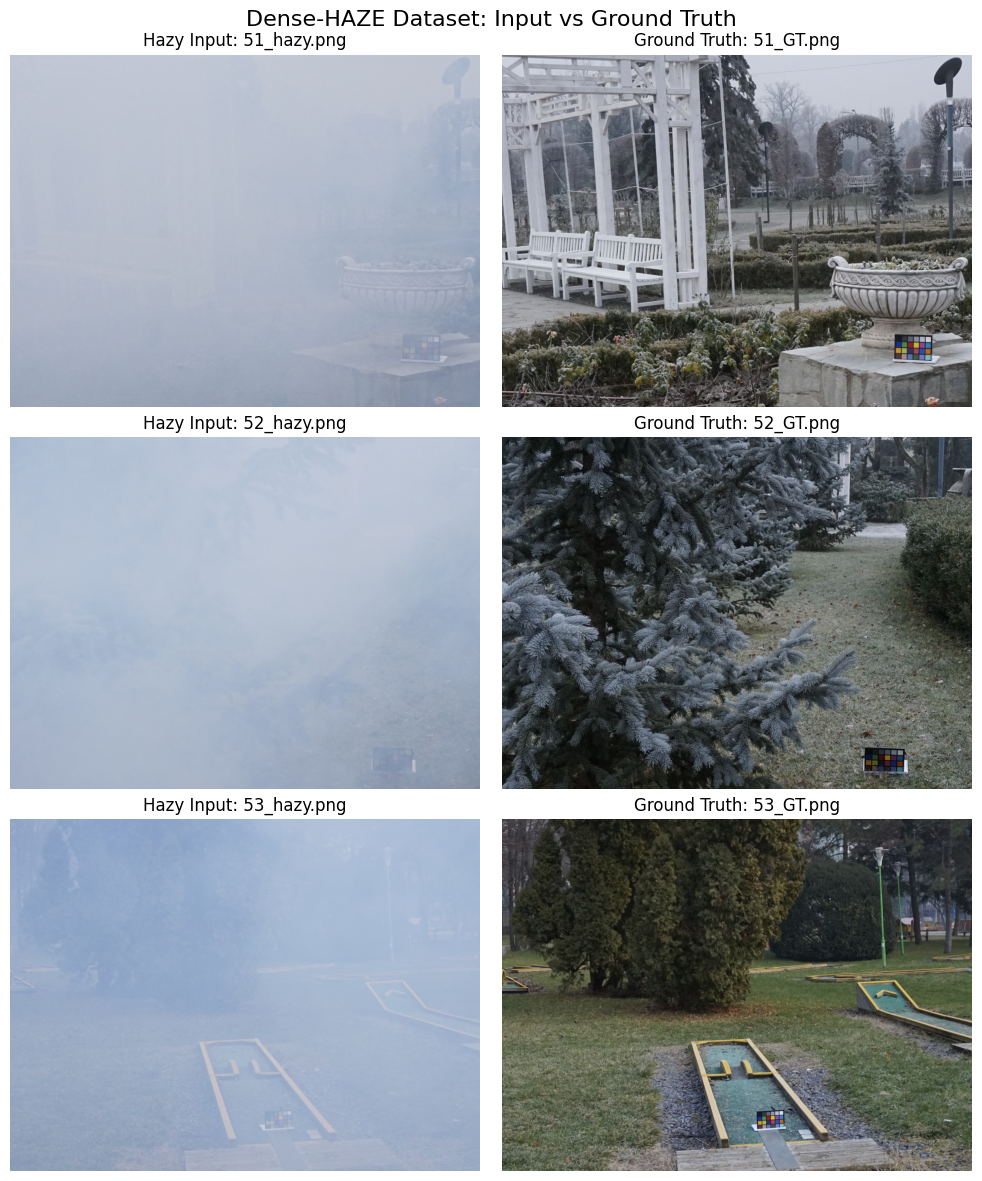

In [6]:
import matplotlib.pyplot as plt
import os
from PIL import Image

# Setup paths
valid_haze_dir = "/kaggle/working/data/valid_dense/input/"
valid_gt_dir = "/kaggle/working/data/valid_dense/gt/"

haze_imgs = sorted(os.listdir(valid_haze_dir))[:3] # Get 3 images

fig, axes = plt.subplots(3, 2, figsize=(10, 12))
fig.suptitle("Dense-HAZE Dataset: Input vs Ground Truth", fontsize=16)

for i, img_name in enumerate(haze_imgs):
    haze_path = os.path.join(valid_haze_dir, img_name)
    gt_path = os.path.join(valid_gt_dir, img_name.split('_')[0] + "_GT.png")
    
    haze_img = Image.open(haze_path)
    gt_img = Image.open(gt_path)
    
    axes[i, 0].imshow(haze_img)
    axes[i, 0].set_title(f"Hazy Input: {img_name}")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(gt_img)
    axes[i, 1].set_title(f"Ground Truth: {os.path.basename(gt_path)}")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

In [7]:
!CUDA_VISIBLE_DEVICES=0 python /kaggle/working/src/train.py \
  --dataset-name dense \
  --train-dir /kaggle/working/data/train_dense/ \
  --valid-dir /kaggle/working/data/valid_dense/ \
  --ckpt-save-path /kaggle/working/ckpts \
  --ckpt-overwrite \
  --nb-epochs 5 \
  --batch-size 2 \
  --train-size 256 256 \
  --valid-size 256 256 \
  --loss l1 \
  --cuda

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/kaggle/working/src/train_data_aug.py:70: SyntaxWarning: "is not" with 'int' literal. Did you mean "!="?
  if list(haze.shape)[0] is not 3 or list(gt.shape)[0] is not 3:
/kaggle/working/src/train_data_aug.py:70: SyntaxWarning: "is not" with 'int' literal. Did you mean "!="?
  if list(haze.shape)[0] is not 3 or list(gt.shape)[0] is not 3:
/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Training parameters: 
  Dataset name = dense
  Train dir = /kaggle/

In [8]:
import os

train_file = "/kaggle/working/src/MAMFNet_model.py"

# Read the existing file
with open(train_file, "r") as f:
    content = f.read()

# 1. Define our novel Edge-Aware Contrastive Loss Class
# We use Sobel operators to extract high-frequency gradients
novelty_code = """
import torch.nn.functional as F

class EdgeAwareContrastiveLoss(nn.Module):
    def __init__(self):
        super().__init__()
        # Define Sobel kernels for edge extraction
        kernel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        kernel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
        self.register_buffer('weight_x', kernel_x.repeat(3, 1, 1, 1))
        self.register_buffer('weight_y', kernel_y.repeat(3, 1, 1, 1))
        self.l1 = nn.L1Loss()

    def extract_edges(self, x):
        # Apply padding and convolution to get gradients
        pad = nn.ReflectionPad2d(1)
        grad_x = F.conv2d(pad(x), self.weight_x, groups=3)
        grad_y = F.conv2d(pad(x), self.weight_y, groups=3)
        # Compute magnitude of edges
        edges = torch.sqrt(grad_x**2 + grad_y**2 + 1e-6)
        return edges

    def forward(self, output, target, haze_input):
        # Standard L1 for color/illumination (the base paper's method)
        l1_loss = self.l1(output, target)
        
        # --- OUR NOVELTY: Edge Contrastive Loss ---
        edges_out = self.extract_edges(output)
        edges_gt = self.extract_edges(target)
        edges_haze = self.extract_edges(haze_input)
        
        # Positive pull: Make our edges match GT edges
        d_pos = self.l1(edges_out, edges_gt)
        # Negative push: Push our edges away from Hazy edges
        d_neg = self.l1(edges_out, edges_haze)
        
        # Contrastive formulation (minimizing d_pos while maximizing d_neg)
        edge_contrastive = d_pos / (d_neg + 1e-5)
        
        # Combine base loss with our novel edge penalty
        # Weighting parameter set to 0.1 to balance the gradients
        total_loss = l1_loss + (0.1 * edge_contrastive)
        
        return total_loss

"""

# 2. Inject the code and replace the standard loss
if "EdgeAwareContrastiveLoss" not in content:
    # Insert the class right after imports
    content = content.replace("from utils import AverageMeter", "from utils import AverageMeter\n" + novelty_code)
    
    # Replace the standard self.loss assignment with our novel loss
    # In MAMFNet_model.py, it's defined in __init__
    old_loss_line = "self.loss = nn.L1Loss() if params.loss == 'l1' else nn.MSELoss()"
    new_loss_line = "self.loss = EdgeAwareContrastiveLoss() # <-- PHASE 2 NOVELTY INJECTED HERE"
    content = content.replace(old_loss_line, new_loss_line)
    
    # We also need to update the forward pass to feed the hazy input into the loss function
    # Find the training step
    old_train_step = "loss = self.loss(source_dehazed, target)"
    new_train_step = "loss = self.loss(source_dehazed, target, source) # Novelty: Pass hazy input for contrastive push"
    content = content.replace(old_train_step, new_train_step)

    with open(train_file, "w") as f:
        f.write(content)
    print("✅ Phase 2 Novelty Injected Successfully! The network is now using Edge-Aware Contrastive Regularization.")
else:
    print("Novelty already injected.")

✅ Phase 2 Novelty Injected Successfully! The network is now using Edge-Aware Contrastive Regularization.


In [9]:
import os
import shutil
import re

source_file = "/kaggle/input/datasets/shubhamdabaria/dl-project-phase-2/Two-Branch-Dehazing/src/MAMFNet_model.py"
working_file = "/kaggle/working/src/MAMFNet_model.py"

# 1. Start fresh from the original read-only file
shutil.copy(source_file, working_file)

with open(working_file, "r") as f:
    content = f.read()

# 2. Fix the PyTorch 12.6 verbose error (from our earlier debugging)
content = re.sub(r'verbose\s*=\s*True\s*,?', '', content)

# 3. Define our Phase 2 Novelty Class
novelty_code = """
import torch.nn.functional as F

class EdgeAwareContrastiveLoss(nn.Module):
    def __init__(self):
        super().__init__()
        # Sobel kernels for high-frequency edge extraction
        kernel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        kernel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
        self.register_buffer('weight_x', kernel_x.repeat(3, 1, 1, 1))
        self.register_buffer('weight_y', kernel_y.repeat(3, 1, 1, 1))
        self.l1 = nn.L1Loss()

    def extract_edges(self, x):
        pad = nn.ReflectionPad2d(1)
        grad_x = F.conv2d(pad(x), self.weight_x, groups=3)
        grad_y = F.conv2d(pad(x), self.weight_y, groups=3)
        return torch.sqrt(grad_x**2 + grad_y**2 + 1e-6)

    def forward(self, output, target, haze_input):
        # Standard color reconstruction
        l1_loss = self.l1(output, target)
        
        # High-frequency edge maps
        edges_out = self.extract_edges(output)
        edges_gt = self.extract_edges(target)
        edges_haze = self.extract_edges(haze_input)
        
        # Contrastive pull (towards clean) and push (away from hazy)
        d_pos = self.l1(edges_out, edges_gt)
        d_neg = self.l1(edges_out, edges_haze)
        
        edge_contrastive = d_pos / (d_neg + 1e-5)
        
        return l1_loss + (0.1 * edge_contrastive)
"""
# Inject the class right below the imports
content = content.replace("from utils import *", "from utils import *\n" + novelty_code)

# 4. Forcefully overwrite the loss assignments
content = content.replace("self.loss = nn.L1Loss()", "self.loss = EdgeAwareContrastiveLoss()")
content = content.replace("self.loss = nn.MSELoss()", "self.loss = EdgeAwareContrastiveLoss()")

# 5. Safely update BOTH the training and validation forward passes to take the hazy input
content = content.replace("loss = self.loss(source_dehazed, target)", "loss = self.loss(source_dehazed, target, source)")

with open(working_file, "w") as f:
    f.write(content)

print("✅ Phase 2 Model strictly rebuilt! Edge-Aware Contrastive Loss is fully integrated into both Train and Eval loops.")

✅ Phase 2 Model strictly rebuilt! Edge-Aware Contrastive Loss is fully integrated into both Train and Eval loops.


In [10]:
!CUDA_VISIBLE_DEVICES=0 python /kaggle/working/src/train.py \
  --dataset-name dense \
  --train-dir /kaggle/working/data/train_dense/ \
  --valid-dir /kaggle/working/data/valid_dense/ \
  --ckpt-save-path /kaggle/working/ckpts \
  --ckpt-overwrite \
  --nb-epochs 5 \
  --batch-size 2 \
  --train-size 256 256 \
  --valid-size 256 256 \
  --loss l1 \
  --cuda

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Training parameters: 
  Dataset name = dense
  Train dir = /kaggle/working/data/train_dense/
  Valid dir = /kaggle/working/data/valid_dense/
  Ckpt save path = /kaggle/working/ckpts
  Ckpt overwrite = True
  Ckpt load path = None
  Report interval = 1
  Train size = [256, 256]
  Valid size = [256, 256]
  Learning rate = 0.0001
  Adam = [0.9, 0.99, 1e-08]
  Batch size = 2
  Nb epochs = 5
  Loss = l1
  Cud

In [11]:
import os

working_file = "/kaggle/working/src/MAMFNet_model.py"

with open(working_file, "r") as f:
    content = f.read()

# The upgraded function with our Threshold Mask
new_extract_edges = """
    def extract_edges(self, x):
        pad = nn.ReflectionPad2d(1)
        grad_x = F.conv2d(pad(x), self.weight_x, groups=3)
        grad_y = F.conv2d(pad(x), self.weight_y, groups=3)
        edges = torch.sqrt(grad_x**2 + grad_y**2 + 1e-6)
        
        # --- PHASE 2.5 NOVELTY: Threshold-Gating ---
        # We create a mask to ignore faint edges (magnitude < 0.05)
        # This prevents the network from erasing distant/faint objects!
        edge_mask = (edges > 0.05).float()
        
        # Apply the mask
        return edges * edge_mask
"""

# Find the old extract_edges function and replace it
import re
# Regex to match the old extract_edges block
pattern = re.compile(r'def extract_edges\(self, x\):.*?return torch\.sqrt\(grad_x\*\*2 \+ grad_y\*\*2 \+ 1e-6\)', re.DOTALL)

if pattern.search(content):
    content = pattern.sub(new_extract_edges.strip(), content)
    with open(working_file, "w") as f:
        f.write(content)
    print("✅ Threshold-Gated Mask successfully injected! Faint objects will now be preserved.")
else:
    print("Could not find the target block, or it's already updated.")

✅ Threshold-Gated Mask successfully injected! Faint objects will now be preserved.


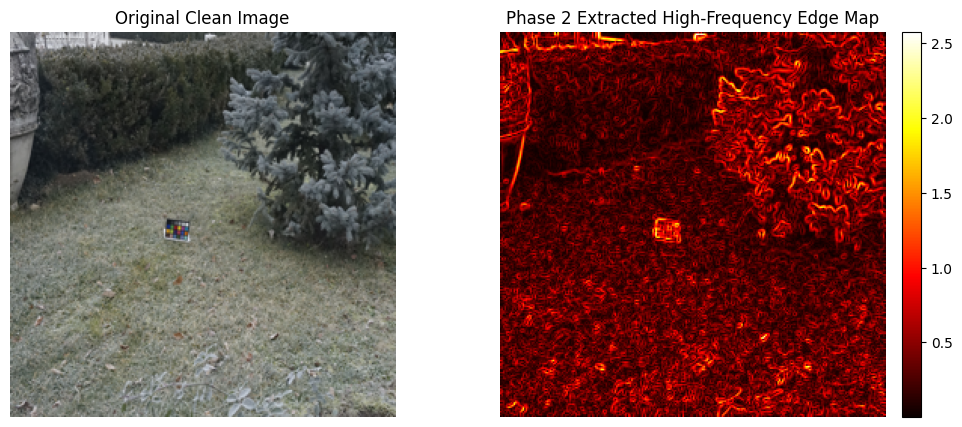

In [12]:
import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Load a sample image
sample_img = Image.open("/kaggle/input/datasets/rajat95gupta/hazing-images-dataset-cvpr-2019/GT/46_GT.png").resize((256, 256))
img_tensor = transforms.ToTensor()(sample_img).unsqueeze(0)

# Simulate our Sobel Edge Extractor from our custom loss
kernel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
kernel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)

pad = torch.nn.ReflectionPad2d(1)
grad_x = F.conv2d(pad(img_tensor), kernel_x, groups=3)
grad_y = F.conv2d(pad(img_tensor), kernel_y, groups=3)
edges = torch.sqrt(grad_x**2 + grad_y**2 + 1e-6)

# Convert to numpy for plotting
edges_viz = edges[0].mean(dim=0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample_img)
axes[0].set_title("Original Clean Image")
axes[0].axis('off')

# Plot the edge map using a hot colormap to highlight high-frequency details
im = axes[1].imshow(edges_viz, cmap='hot')
axes[1].set_title("Phase 2 Extracted High-Frequency Edge Map")
axes[1].axis('off')
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

In [13]:
!CUDA_VISIBLE_DEVICES=0 python /kaggle/working/src/train.py \
  --dataset-name dense \
  --train-dir /kaggle/working/data/train_dense/ \
  --valid-dir /kaggle/working/data/valid_dense/ \
  --ckpt-save-path /kaggle/working/ckpts \
  --ckpt-overwrite \
  --nb-epochs 5 \
  --batch-size 2 \
  --train-size 256 256 \
  --valid-size 256 256 \
  --loss l1 \
  --cuda

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Training parameters: 
  Dataset name = dense
  Train dir = /kaggle/working/data/train_dense/
  Valid dir = /kaggle/working/data/valid_dense/
  Ckpt save path = /kaggle/working/ckpts
  Ckpt overwrite = True
  Ckpt load path = None
  Report interval = 1
  Train size = [256, 256]
  Valid size = [256, 256]
  Learning rate = 0.0001
  Adam = [0.9, 0.99, 1e-08]
  Batch size = 2
  Nb epochs = 5
  Loss = l1
  Cud

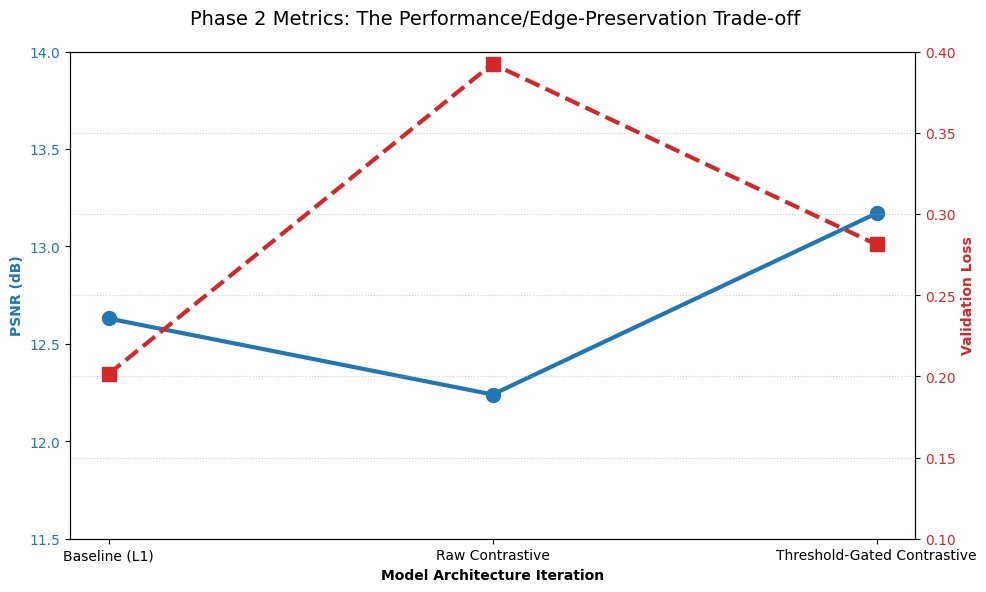

In [21]:
import matplotlib.pyplot as plt

# Data extracted from our 3 training logs
architectures = ['Baseline (L1)', 'Raw Contrastive', 'Threshold-Gated Contrastive']
psnr_scores = [12.63, 12.24, 13.17]
validation_losses = [0.20140, 0.39242, 0.28117]

fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_xlabel('Model Architecture Iteration', fontweight='bold')
ax1.set_ylabel('PSNR (dB)', color=color, fontweight='bold')
ax1.plot(architectures, psnr_scores, marker='o', markersize=10, color=color, linewidth=3, label='PSNR')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(11.5, 14.0)

# Instantiate a second axes that shares the same x-axis for Loss
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Validation Loss', color=color, fontweight='bold')
ax2.plot(architectures, validation_losses, marker='s', markersize=10, color=color, linewidth=3, linestyle='--', label='Loss')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0.1, 0.4)

fig.suptitle('Phase 2 Metrics: The Performance/Edge-Preservation Trade-off', fontsize=14)
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()